*Ana Rosa Pérez y Albert Pineda*

## Proyecto APA Evaluación preliminar

# Predicción de Insuficiencia cardíaca crónica tras infarto de miocardio 

El conjunto de datos que hemos seleccionado es: https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications , **complicaciones de infarto de miocardio**. Este conjunto estudia varios pacientes en donde algunos han sufrido infarto de miocardios (o varios) y busca predecir las complicaciones que se pueden sufrir.

Las complicaciones que nos indica la web del dataset junto al número de casos positivos son las siguientes:

| Variable objetivo | Complicación / desenlace | Casos negativos (0) | Casos positivos (1) | % positivos |
|---|---|---:|---:|---|
| FIBR_PREDS | Fibrilación auricular | 1530 | 170 | 10.00% |
| PREDS_TAH | Taquicardia supraventricular | 1680 | 20 | 1.18% | 
| JELUD_TAH | Taquicardia ventricular | 1658 | 42 | 2.47% | 
| FIBR_JELUD | Fibrilación ventricular | 1629 | 71 | 4.18% | 
| A_V_BLOK | Bloqueo AV de tercer grado | 1643 | 57 | 3.35% | 
| OTEK_LANC | Edema pulmonar | 1541 | 159 | 9.35% | 
| RAZRIV | Rotura miocárdica | 1646 | 54 | 3.18% | 
| DRESSLER | Síndrome de Dressler | 1625 | 75 | 4.41% | 
| ZSN | Insuficiencia cardíaca crónica | 1306 | 394 | 23.18% | 
| REC_IM | Recaída del infarto de miocardio | 1541 | 159 | 9.35% |
| P_IM_STEN | Angina posterior al infarto | 1552 | 148 | 8.71% | 
| LET_IS | Desenlace mortal (causa) | 1429* | 271* | 15.94%* |

Con esta tabla, decidimos que la variable a estudiar por el momento es la Insuficiencia cardíaca cronica (ZSN), pues es la que mayor porcentaje de positivos tiene. Como esta es una variable binaria, nuestro trabajo será de **clasificación binaria**. El problema que seleccionamos a través de este dataset será: **predecir Insuficiencia cardíaca crónica tras infarto de miocardio en el momento del ingreso** .

### Atributos asociados con el tiempo
En estos datos tenemos bastantes variables que tienen que ver con el tiempo y que pueden ser razonables o no para lo que nos interesa estudiar y en qué momento queremos predecir. Por ejemplo, no podemos utilizar una variable de *medicina dada el tercer dia tras el ingreso* si nuestro modelo predice en el día de ingreso. Las variables relacionadas al tiempo junto a su información temporal son:

| Variable | Significado | Tipo de información temporal |
|---|---|---|
| TIME_B_S | Tiempo transcurrido desde el inicio del episodio coronario hasta la llegada al hospital. | Tiempo previo al ingreso |
| STENOK_AN | Antecedentes de angina de esfuerzo y cuándo se produjeron. | Historial clínico |
| DLIT_AG | Duración de la hipertensión arterial. | Duración de una enfermedad previa |
| IBS_POST | Presencia y tipo de enfermedad coronaria en los días o semanas anteriores al ingreso. | Historial clínico reciente |
| R_AB_1_n | Número de recaídas del dolor durante las primeras horas de hospitalización. | Evolución hospitalaria inicial |
| R_AB_2_n | Número de recaídas del dolor durante el segundo día de hospitalización. | Evolución hospitalaria, día 2 |
| R_AB_3_n | Número de recaídas del dolor durante el tercer día de hospitalización. | Evolución hospitalaria, día 3 |
| NA_R_1_n | Uso de opioides en la unidad de cuidados intensivos durante las primeras horas. | Tratamiento hospitalario inicial |
| NA_R_2_n | Uso de opioides en la unidad de cuidados intensivos durante el segundo día. | Tratamiento hospitalario, día 2 |
| NA_R_3_n | Uso de opioides en la unidad de cuidados intensivos durante el tercer día. | Tratamiento hospitalario, día 3 |
| NOT_NA_1_n | Uso de antiinflamatorios no esteroideos durante las primeras horas en cuidados intensivos. | Tratamiento hospitalario inicial |
| NOT_NA_2_n | Uso de antiinflamatorios no esteroideos durante el segundo día en cuidados intensivos. | Tratamiento hospitalario, día 2 |
| NOT_NA_3_n | Uso de antiinflamatorios no esteroideos durante el tercer día en cuidados intensivos. | Tratamiento hospitalario, día 3 |

Consideramos que es más útil realizar un predictor utilizado en el **momento del ingreso**, es por eso que las variables de tratamiento hospitalario las eliminaremos, ya que describen algo que aún no habría ocurrido.



### Desbalance entre clases

La variable objetivo `ZSN` representa la presencia o ausencia de insuficiencia cardíaca crónica.

Según la distribución del dataset, hay 394 pacientes positivos y 1.306 negativos, sobre un total de 1.700 pacientes:

| Clase | Significado | Número de pacientes | Porcentaje |
|---|---|---:|---:|
| 0 | Sin insuficiencia cardíaca crónica | 1.306 | 76,82 % |
| 1 | Con insuficiencia cardíaca crónica | 394 | 23,18 % |
| **Total** | | **1.700** | **100 %** |

Existe, por tanto, un desbalance moderado entre las clases. No es un desequilibrio extremo, pero sí suficientemente importante como para tenerlo en cuenta al entrenar y evaluar el modelo. El problema es que el modelo pueda convertirse extremadamente positivo y que apenas sea capaz de detectar casos de insuficiencia cardiaca crónica.

Durante el preprocesamiento se conservará la distribución de clases y se utilizará una partición estratificada para mantener proporciones similares de ambas clases en los conjuntos de entrenamiento y prueba. Si fuera necesario aplicar técnicas de sobremuestreo o submuestreo, estas se realizarán únicamente sobre los datos de entrenamiento.

Además vemos que el conjunto presenta en casi todas las variables valores perdidos, por lo que tendremos que imputar esos datos si queremos no perderlos.

In [1]:
import pandas as pd
from pandas import read_csv

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn import set_config

from sklearn.metrics import  ConfusionMatrixDisplay,\
                  classification_report,  RocCurveDisplay, PrecisionRecallDisplay,\
                    accuracy_score, f1_score, precision_score, recall_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB, GaussianNB, CategoricalNB, MultinomialNB

from sklearn.model_selection import GridSearchCV

from yellowbrick.target.feature_correlation import feature_correlation
from yellowbrick.classifier import precision_recall_curve

import warnings

set_config(display='text')
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 16})
pd.set_option('display.precision', 3)

In [2]:
def save_results(clf, X_test, y_test, nclf, df):
    if hasattr(clf, 'best_score_'):
        df.loc[nclf,'train XV acc'] = clf.best_score_
    else:
        df.loc[nclf,'train XV acc'] = np.nan
    df.loc[nclf,'test acc'] = accuracy_score(y_test, clf.predict(X_test))
    df.loc[nclf,'precision score (M)'] = precision_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'recall score (M)'] = recall_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'f1 score (M)'] = f1_score(y_test, clf.predict(X_test), average='macro')
    return df

results_df = pd.DataFrame()

niter = 15
cv = 5

### Obtención de los datos

Utilizamos la función de importación proporcionada por el repositorio de UC Irvine

In [3]:
pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Cargar dataset
myocardial_infarction_complications = fetch_ucirepo(id=579)

X = myocardial_infarction_complications.data.features
y = myocardial_infarction_complications.data.targets

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())
display(y.head())

Dimensiones de X: (1700, 111)
Dimensiones de y: (1700, 12)


,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0
2,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,2.0,...,3.0,2.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
3,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
4,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


,FIBR_PREDS,PREDS_TAH,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
TARGET = "ZSN"
df = X.copy().reset_index(drop=True)

# Añadir el target al DataFrame auxiliar
df[TARGET] = pd.to_numeric(
    y[TARGET].reset_index(drop=True),
    errors="coerce"
)

# Eliminar el identificador: no tiene significado clínico predictivo
df = df.drop(columns=["ID"], errors="ignore")

# Revisar la distribución del target
print("Distribución de ZSN:")
display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("ZSN")
    .to_frame("Número de pacientes")
)

print("\nValores ausentes en ZSN:", df[TARGET].isna().sum())

Distribución de ZSN:


,Número de pacientes
ZSN,
0,1306
1,394



Valores ausentes en ZSN: 0


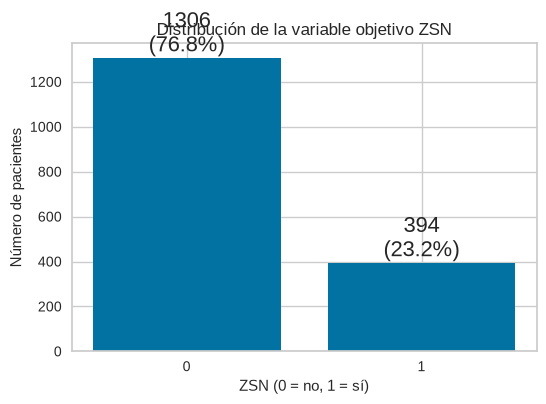

In [6]:
counts = df[TARGET].value_counts().sort_index()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    counts.index.astype(str),
    counts.values
)

ax.set_title("Distribución de la variable objetivo ZSN")
ax.set_xlabel("ZSN (0 = no, 1 = sí)")
ax.set_ylabel("Número de pacientes")

for bar, count, percentage in zip(
    bars, counts.values, percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.show()

Número de variables permitidas: 102


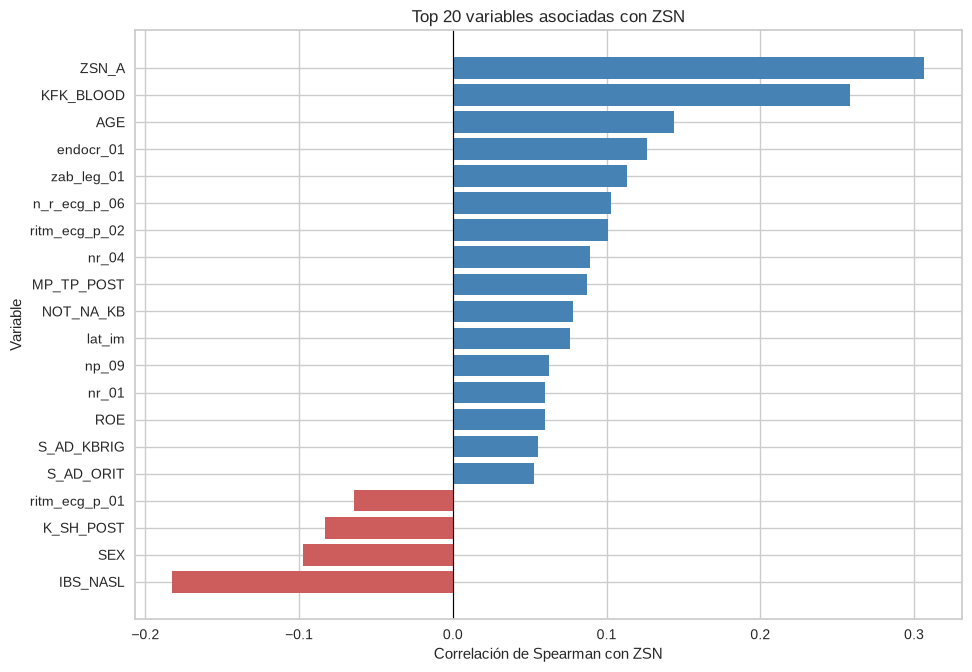

,Correlación con ZSN,Correlación_absoluta
ZSN_A,0.307,0.307
KFK_BLOOD,0.258,0.258
IBS_NASL,-0.183,0.183
AGE,0.144,0.144
endocr_01,0.126,0.126
...,...,...
fibr_ter_05,0.002,0.002
n_p_ecg_p_10,0.002,0.002
SIM_GIPERT,-0.002,0.002
zab_leg_06,-0.001,0.001


In [7]:

# Variables permitidas: columnas originales 2 a 112, que no tienen que ver con tiempo ni complicaciones
excluded_columns = {93, 94, 95, 100, 101, 102, 103, 104, 105}

# X contiene las variables originales 2 a 112.
# Como Python empieza a contar desde 0, la columna original 2
# corresponde a X.iloc[:, 0].
excluded_positions = {col - 2 for col in excluded_columns}

feature_cols = [
    col for pos, col in enumerate(X.columns)
    if pos not in excluded_positions
]

print("Número de variables permitidas:", len(feature_cols))

# Preparar datos para la exploración visual.
df_visual = X[feature_cols].copy().reset_index(drop=True)

for col in feature_cols:
    df_visual[col] = pd.to_numeric(df_visual[col], errors="coerce")

df_visual[TARGET] = pd.to_numeric(
    y[TARGET].reset_index(drop=True),
    errors="coerce"
)

# Correlación de Spearman de todas las variables con ZSN.
corr_target = (
    df_visual[feature_cols + [TARGET]]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .dropna()
)

# Ordenar por fuerza de asociación, sin distinguir el signo.
corr_target = corr_target.reindex(
    corr_target.abs().sort_values(ascending=False).index
)

# Mostrar las 20 variables con mayor correlación absoluta.
top_n = min(20, len(corr_target))
top_corr = corr_target.head(top_n).sort_values()

plt.figure(figsize=(10, max(6, top_n * 0.35)))

colors = [
    "steelblue" if value >= 0 else "indianred"
    for value in top_corr.values
]

plt.barh(top_corr.index, top_corr.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlación de Spearman con ZSN")
plt.ylabel("Variable")
plt.title(f"Top {top_n} variables asociadas con ZSN")
plt.tight_layout()
plt.show()

# Tabla con las correlaciones de todas las variables permitidas.
display(
    corr_target.rename("Correlación con ZSN")
    .to_frame()
    .assign(
        Correlación_absoluta=lambda d: d.iloc[:, 0].abs()
    )
)

Utilizamos la correlación de Spearman ya que consideramos que una lineal como la de Pearson no es muy útil en datos de estudio clínico de muchos tipos con seguramente varias relaciones no lineales. Aún así, es importante destacar que hay algunas variables categóricas codificadas en números y aquí Pearson no lo hace tan bien, por eso, esta visualización es importante verla con precaución.

Sobre las variables con más correlación que podemos ver, tenemos ZSN_A que representa antecedentes de insuficiencia cardíaca crónica. Esta asociación es coherente, ya que ambas variables están relacionadas con la misma condición clínica, aunque en momentos o contextos distintos. Le sigue KFK_BLOOD (0,258), que mide la concentración de creatina fosfoquinasa en sangre y presenta una asociación positiva moderada-baja con el objetivo.

IBS_NASL (-0,183), que indica antecedentes familiares de cardiopatía isquémica, presenta una asociación negativa débil. AGE (0,144) muestra una asociación positiva débil, lo que sugiere que una mayor edad tiende a relacionarse con la presencia de insuficiencia cardíaca crónica. Finalmente tenemos endocr_01 (0,126), que indica antecedentes de diabetes, también presenta una asociación positiva débil.

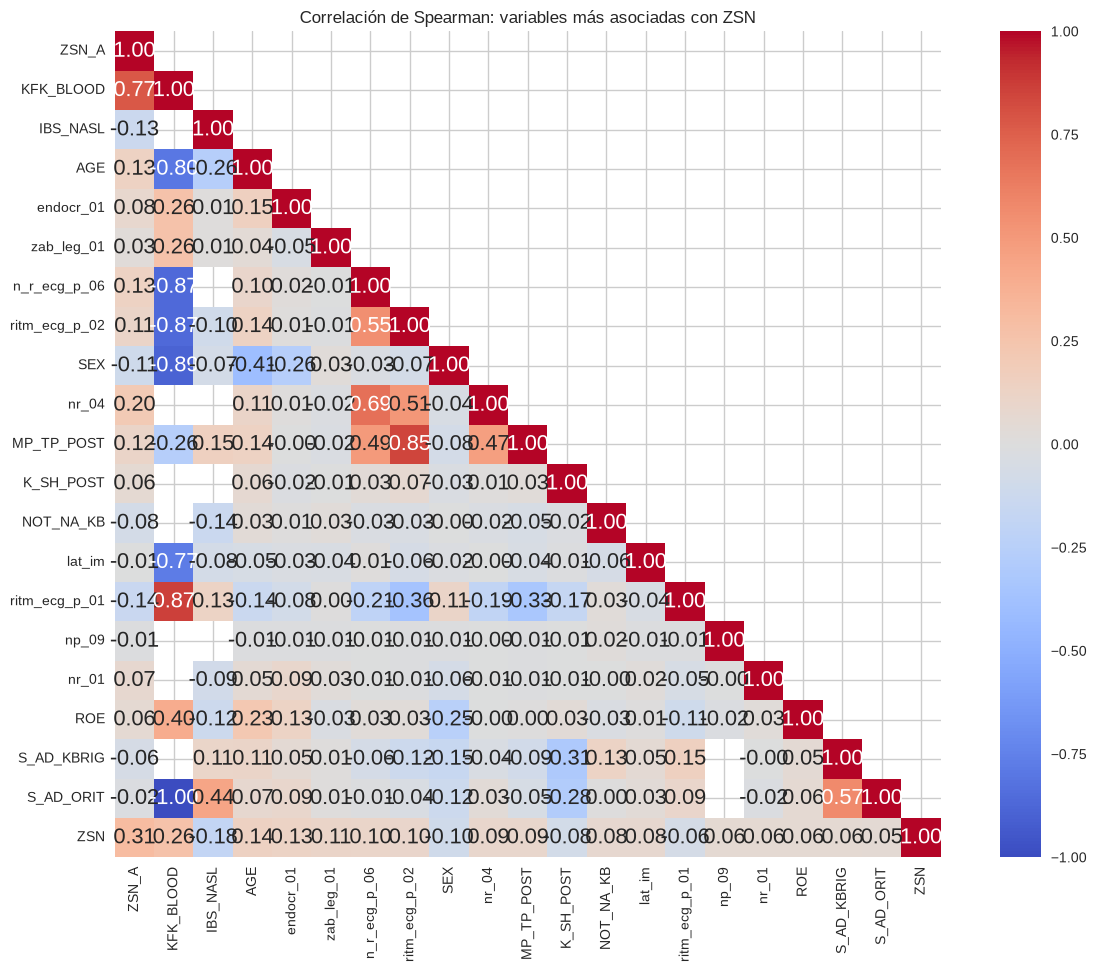

In [8]:

# Seleccionar las 20 variables con mayor asociación absoluta con ZSN.
top_features = corr_target.head(
    min(20, len(corr_target))
).index.tolist()

# Matriz de correlación entre las variables seleccionadas y el target.
corr_matrix = df_visual[top_features + [TARGET]].corr(
    method="spearman"
)

# Mostrar la mitad inferior de la matriz.
mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title(
    "Correlación de Spearman: variables más asociadas con ZSN"
)
plt.tight_layout()
plt.show()


In [9]:

valid = y[TARGET].notna()

X_model = X.loc[valid, feature_cols].copy()
y_model = y.loc[valid, TARGET].astype(int).copy()


X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.30,
    random_state=42,
    stratify=y_model
)

print("Variables seleccionadas:", len(feature_cols))
print("Train:", X_train.shape)
print("Test:", X_test.shape)


Variables seleccionadas: 102
Train: (1190, 102)
Test: (510, 102)


In [10]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer

continuous_cols = [
    col for col in [
        "AGE", "S_AD_KBRIG", "D_AD_KBRIG",
        "S_AD_ORIT", "D_AD_ORIT",
        "K_BLOOD", "NA_BLOOD", "ALT_BLOOD",
        "AST_BLOOD", "KFK_BLOOD", "L_BLOOD", "ROE"
    ]
    if col in X_train.columns
]

categorical_cols = [
    col for col in X_train.columns
    if col not in continuous_cols
]

# Asegurar formato numérico.
for col in X_train.columns:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

# Imputar continuas con la mediana y categóricas con la moda.
imp_cont = SimpleImputer(strategy="median")
imp_cat = SimpleImputer(strategy="most_frequent")

train_cont = pd.DataFrame(
    imp_cont.fit_transform(X_train[continuous_cols]),
    columns=continuous_cols, index=X_train.index
)
test_cont = pd.DataFrame(
    imp_cont.transform(X_test[continuous_cols]),
    columns=continuous_cols, index=X_test.index
)

train_cat = pd.DataFrame(
    imp_cat.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols, index=X_train.index
)
test_cat = pd.DataFrame(
    imp_cat.transform(X_test[categorical_cols]),
    columns=categorical_cols, index=X_test.index
)

Separamos las variables continuas de las categóricas para aplicar una estrategia de imputación adecuada a cada tipo. Las variables continuas se imputan con la mediana, que es menos sensible a valores extremos, mientras que las categóricas se imputan con la moda, es decir, el valor más frecuente. La moda/mediana en columnas con muchísimos nulos las convierte casi en constantes pero aqui tenemos más del 90% de datos existentes.

In [11]:
# Discretizar las continuas: los intervalos se aprenden solo con train.
disc = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    subsample=None
)

train_cont = pd.DataFrame(
    disc.fit_transform(train_cont),
    columns=continuous_cols, index=X_train.index
).astype(int)

test_cont = pd.DataFrame(
    disc.transform(test_cont),
    columns=continuous_cols, index=X_test.index
).astype(int)

Se utiliza KBinsDiscretizer para transformar las variables continuas en cinco intervalos según sus cuantiles. Así, los valores numéricos se convierten en categorías representadas por enteros del 0 al 4, facilitando su uso con CategoricalNB. Los límites de los intervalos se calculan únicamente con el conjunto de entrenamiento y se aplican después al conjunto de test.

In [14]:
X_train_nb = pd.concat([train_cont, train_cat], axis=1)
X_test_nb = pd.concat([test_cont, test_cat], axis=1)

for col in categorical_cols:
    X_train_nb[col] = X_train_nb[col].astype(int)
    X_test_nb[col] = X_test_nb[col].astype(int)

X_test_nb = X_test_nb[X_train_nb.columns]

print("Valores ausentes en train:", X_train_nb.isna().sum().sum())
print("Valores ausentes en test:", X_test_nb.isna().sum().sum())


Valores ausentes en train: 0
Valores ausentes en test: 0


En este bloque se unen las variables continuas discretizadas con las categóricas imputadas para reconstruir los conjuntos de entrenamiento y test

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [23]:
min_cats = np.maximum(X_train_nb.max().values, X_test_nb.max().values) + 1

model_cat = CategoricalNB(alpha=1.0, min_categories=min_cats)
model_cat.fit(X_train_nb, y_train)
y_pred_cat = model_cat.predict(X_test_nb)
print("Accuracy:", round(model_cat.score(X_test_nb, y_test), 4))

Accuracy: 0.7804


              precision    recall  f1-score   support

     Sin ZSN       0.83      0.90      0.86       392
     Con ZSN       0.54      0.37      0.44       118

    accuracy                           0.78       510
   macro avg       0.68      0.64      0.65       510
weighted avg       0.76      0.78      0.77       510

ROC AUC: 0.6985
Balanced acc: 0.638


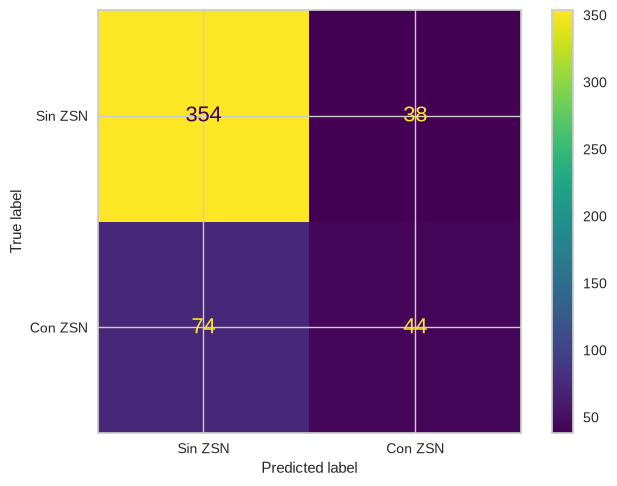

In [24]:
from sklearn.metrics import classification_report, roc_auc_score, balanced_accuracy_score

print(classification_report(y_test, y_pred_cat, target_names=["Sin ZSN", "Con ZSN"]))
print("ROC AUC:", round(roc_auc_score(y_test, model_cat.predict_proba(X_test_nb)[:, 1]), 4))
print("Balanced acc:", round(balanced_accuracy_score(y_test, y_pred_cat), 4))

ConfusionMatrixDisplay.from_estimator(model_cat, X_test_nb, y_test,
                                      display_labels=["Sin ZSN", "Con ZSN"])

Usando un Categorical Naive Byes vemos que con un 76,9 % de pacientes sin ZSN, predecir siempre «no» daría 0.769, así que 0.78 es prácticamente la línea base.
El modelo detecta solo el 37 % de los casos de ZSN (44 de 118) y deja escapar 74. Para un problema clínico, es el error más costoso. Descarta bien a los sanos. Acierta 354 de 392 pacientes sin ZSN (especificidad ≈ 90 %). Casi todo el acierto del modelo viene de la clase mayoritaria.

In [26]:
from sklearn.impute import SimpleImputer

imp_cont_g = SimpleImputer(strategy="median")
imp_cat_g  = SimpleImputer(strategy="most_frequent")

Xtr_cont = pd.DataFrame(imp_cont_g.fit_transform(X_train[continuous_cols]),
                        columns=continuous_cols, index=X_train.index)
Xte_cont = pd.DataFrame(imp_cont_g.transform(X_test[continuous_cols]),
                        columns=continuous_cols, index=X_test.index)

Xtr_cat = pd.DataFrame(imp_cat_g.fit_transform(X_train[categorical_cols]),
                       columns=categorical_cols, index=X_train.index)
Xte_cat = pd.DataFrame(imp_cat_g.transform(X_test[categorical_cols]),
                       columns=categorical_cols, index=X_test.index)

X_train_imp = pd.concat([Xtr_cont, Xtr_cat], axis=1)
X_test_imp  = pd.concat([Xte_cont, Xte_cat], axis=1)[X_train_imp.columns]

print("NaN train/test:", X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

NaN train/test: 0 0


In [27]:
gnb = GaussianNB()
gnb.best_score_ = np.mean(cross_val_score(gnb,X_train_imp,y_train,cv=10))
print(gnb.best_score_)

0.31512605042016806


In [28]:
gnb_model = GaussianNB().fit(X_train_imp, y_train)
gnb_model.best_score_ = gnb.best_score_

print('Priors:', gnb_model.class_prior_)
print('Means:\n')
means =pd.DataFrame(gnb_model.theta_)
means.columns=X_train_imp.columns
means

Priors: [0.76806723 0.23193277]
Means:



,AGE,S_AD_KBRIG,D_AD_KBRIG,S_AD_ORIT,D_AD_ORIT,K_BLOOD,NA_BLOOD,ALT_BLOOD,AST_BLOOD,KFK_BLOOD,...,NOT_NA_KB,LID_KB,NITR_S,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,61.111,139.327,80.826,134.278,82.445,4.182,136.316,0.464,0.260,1.602,...,0.804,0.223,0.111,0.267,0.132,0.659,0.734,0.752,0.014,0.181
1,64.797,139.873,81.069,135.399,83.225,4.137,136.500,0.508,0.265,1.601,...,0.855,0.279,0.123,0.301,0.105,0.721,0.652,0.754,0.007,0.243


In [32]:
from sklearn.metrics import classification_report
print(classification_report(y_test, gnb_model.predict(X_test_imp),
                            target_names=['Sin ZSN', 'Con ZSN']))
results_df = save_results(gnb_model, X_test_imp, y_test, 'GNB', results_df)

              precision    recall  f1-score   support

     Sin ZSN       0.87      0.15      0.25       392
     Con ZSN       0.25      0.92      0.39       118

    accuracy                           0.33       510
   macro avg       0.56      0.54      0.32       510
weighted avg       0.72      0.33      0.28       510



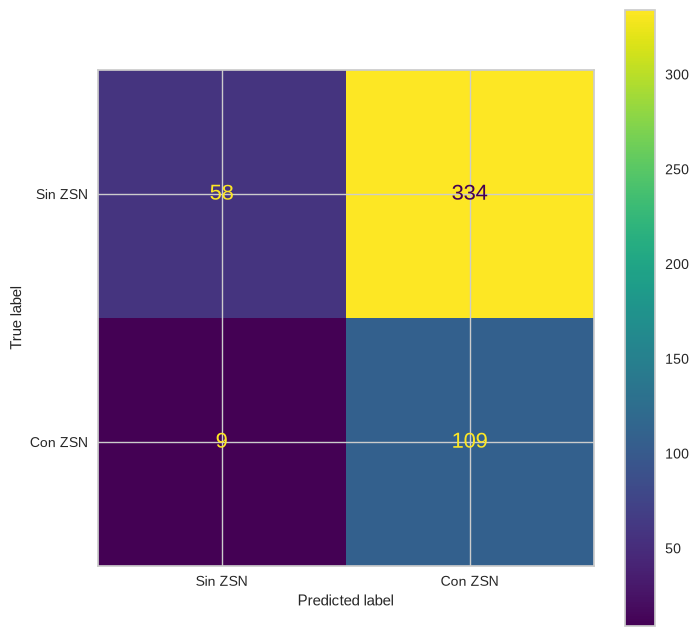

In [33]:
plt.figure(figsize=(8,8))
ConfusionMatrixDisplay.from_estimator(gnb_model, X_test_imp, y_test,
                                      display_labels=['Sin ZSN', 'Con ZSN'],
                                      ax=plt.subplot())

Predice ZSN en 443 de 510 pacientes (87 %), cuando la prevalencia real es del 23 %. Casi todo lo etiqueta como enfermo.
El recall de 0.92 es engañoso. Detecta a 109 de 118 enfermos porque marca a casi todo el mundo. La precisión es 0.25, apenas por encima de la prevalencia (0.23), así que su alarma casi no aporta información. El accuracy es 0.33, muy por debajo del 0.77 que se consigue prediciendo siempre que no.

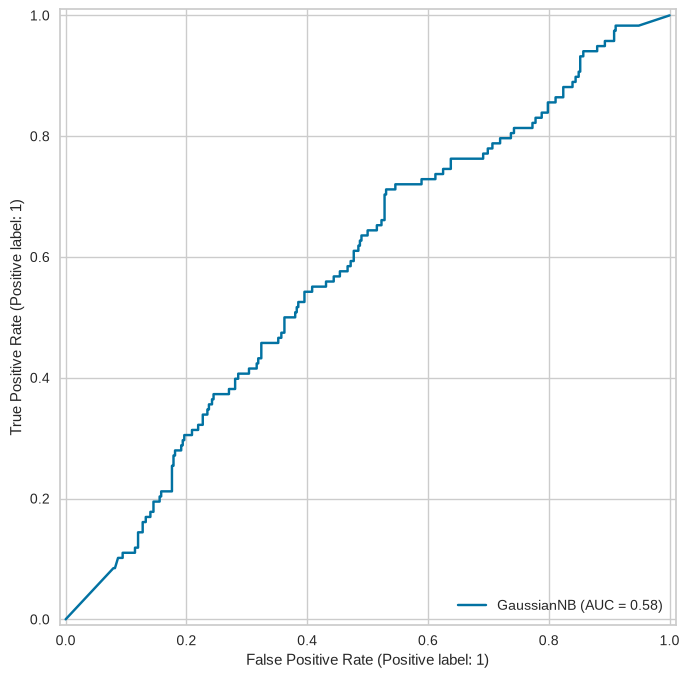

In [34]:
plt.figure(figsize=(8,8))
RocCurveDisplay.from_estimator(gnb_model, X_test_imp, y_test,
                               pos_label=1, ax=plt.subplot())

## Conclusión de evaluación inicial
Con las variables disponibles, Naive Bayes categórico (AUC 0.70, balanced accuracy 0.64) rinde mejor que Gaussiano (AUC 0.58, accuracy 0.33). El Gaussiano asume normalidad en variables mayoritariamente binarias y ordinales, y acaba clasificando como positivo a casi todos los pacientes. Ninguno supera a un clasificador trivial de accuracy 0.77.

Con esto vemos que la representación es más importante que el modelo, ya que hay alta diferencia entre estos dos naive bayes. Tenemos pocos datos, según la correlación de variables de Spearman no hay ninguna variable con una correlación fuerte que nos ayude a afinar mucho más el clasificador.
